# Polynomial Regression / Diamonds Polynomial Regression

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `diamonds.csv`.  
**Methods referenced:** `LinearRegression`, `PolynomialFeatures`, `Pipeline`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [2]:
df = pd.read_csv("diamonds.csv")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [4]:
df = df[(df[['x','y','z']] != 0).all(axis=1)]

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 53920 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53920 non-null  float64
 1   cut      53920 non-null  object 
 2   color    53920 non-null  object 
 3   clarity  53920 non-null  object 
 4   depth    53920 non-null  float64
 5   table    53920 non-null  float64
 6   price    53920 non-null  int64  
 7   x        53920 non-null  float64
 8   y        53920 non-null  float64
 9   z        53920 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.5+ MB


In [6]:
df['volume'] = df['x'] * df['y'] * df['z']

In [7]:
df.corr(numeric_only = True)

,carat,depth,table,price,x,y,z,volume
carat,1.000000,0.028259,0.181646,0.921592,0.977779,0.953991,0.961048,0.978280
depth,0.028259,1.000000,-0.295733,-0.010729,-0.025017,-0.029069,0.095023,0.009039
table,0.181646,-0.295733,1.000000,0.127245,0.196097,0.184493,0.152483,0.167809
price,0.921592,-0.010729,0.127245,1.000000,0.887231,0.867864,0.868206,0.904255
x,0.977779,-0.025017,0.196097,0.887231,1.000000,0.974918,0.975435,0.958533
y,0.953991,-0.029069,0.184493,0.867864,0.974918,1.000000,0.956744,0.977016
z,0.961048,0.095023,0.152483,0.868206,0.975435,0.956744,1.000000,0.951912
volume,0.978280,0.009039,0.167809,0.904255,0.958533,0.977016,0.951912,1.000000


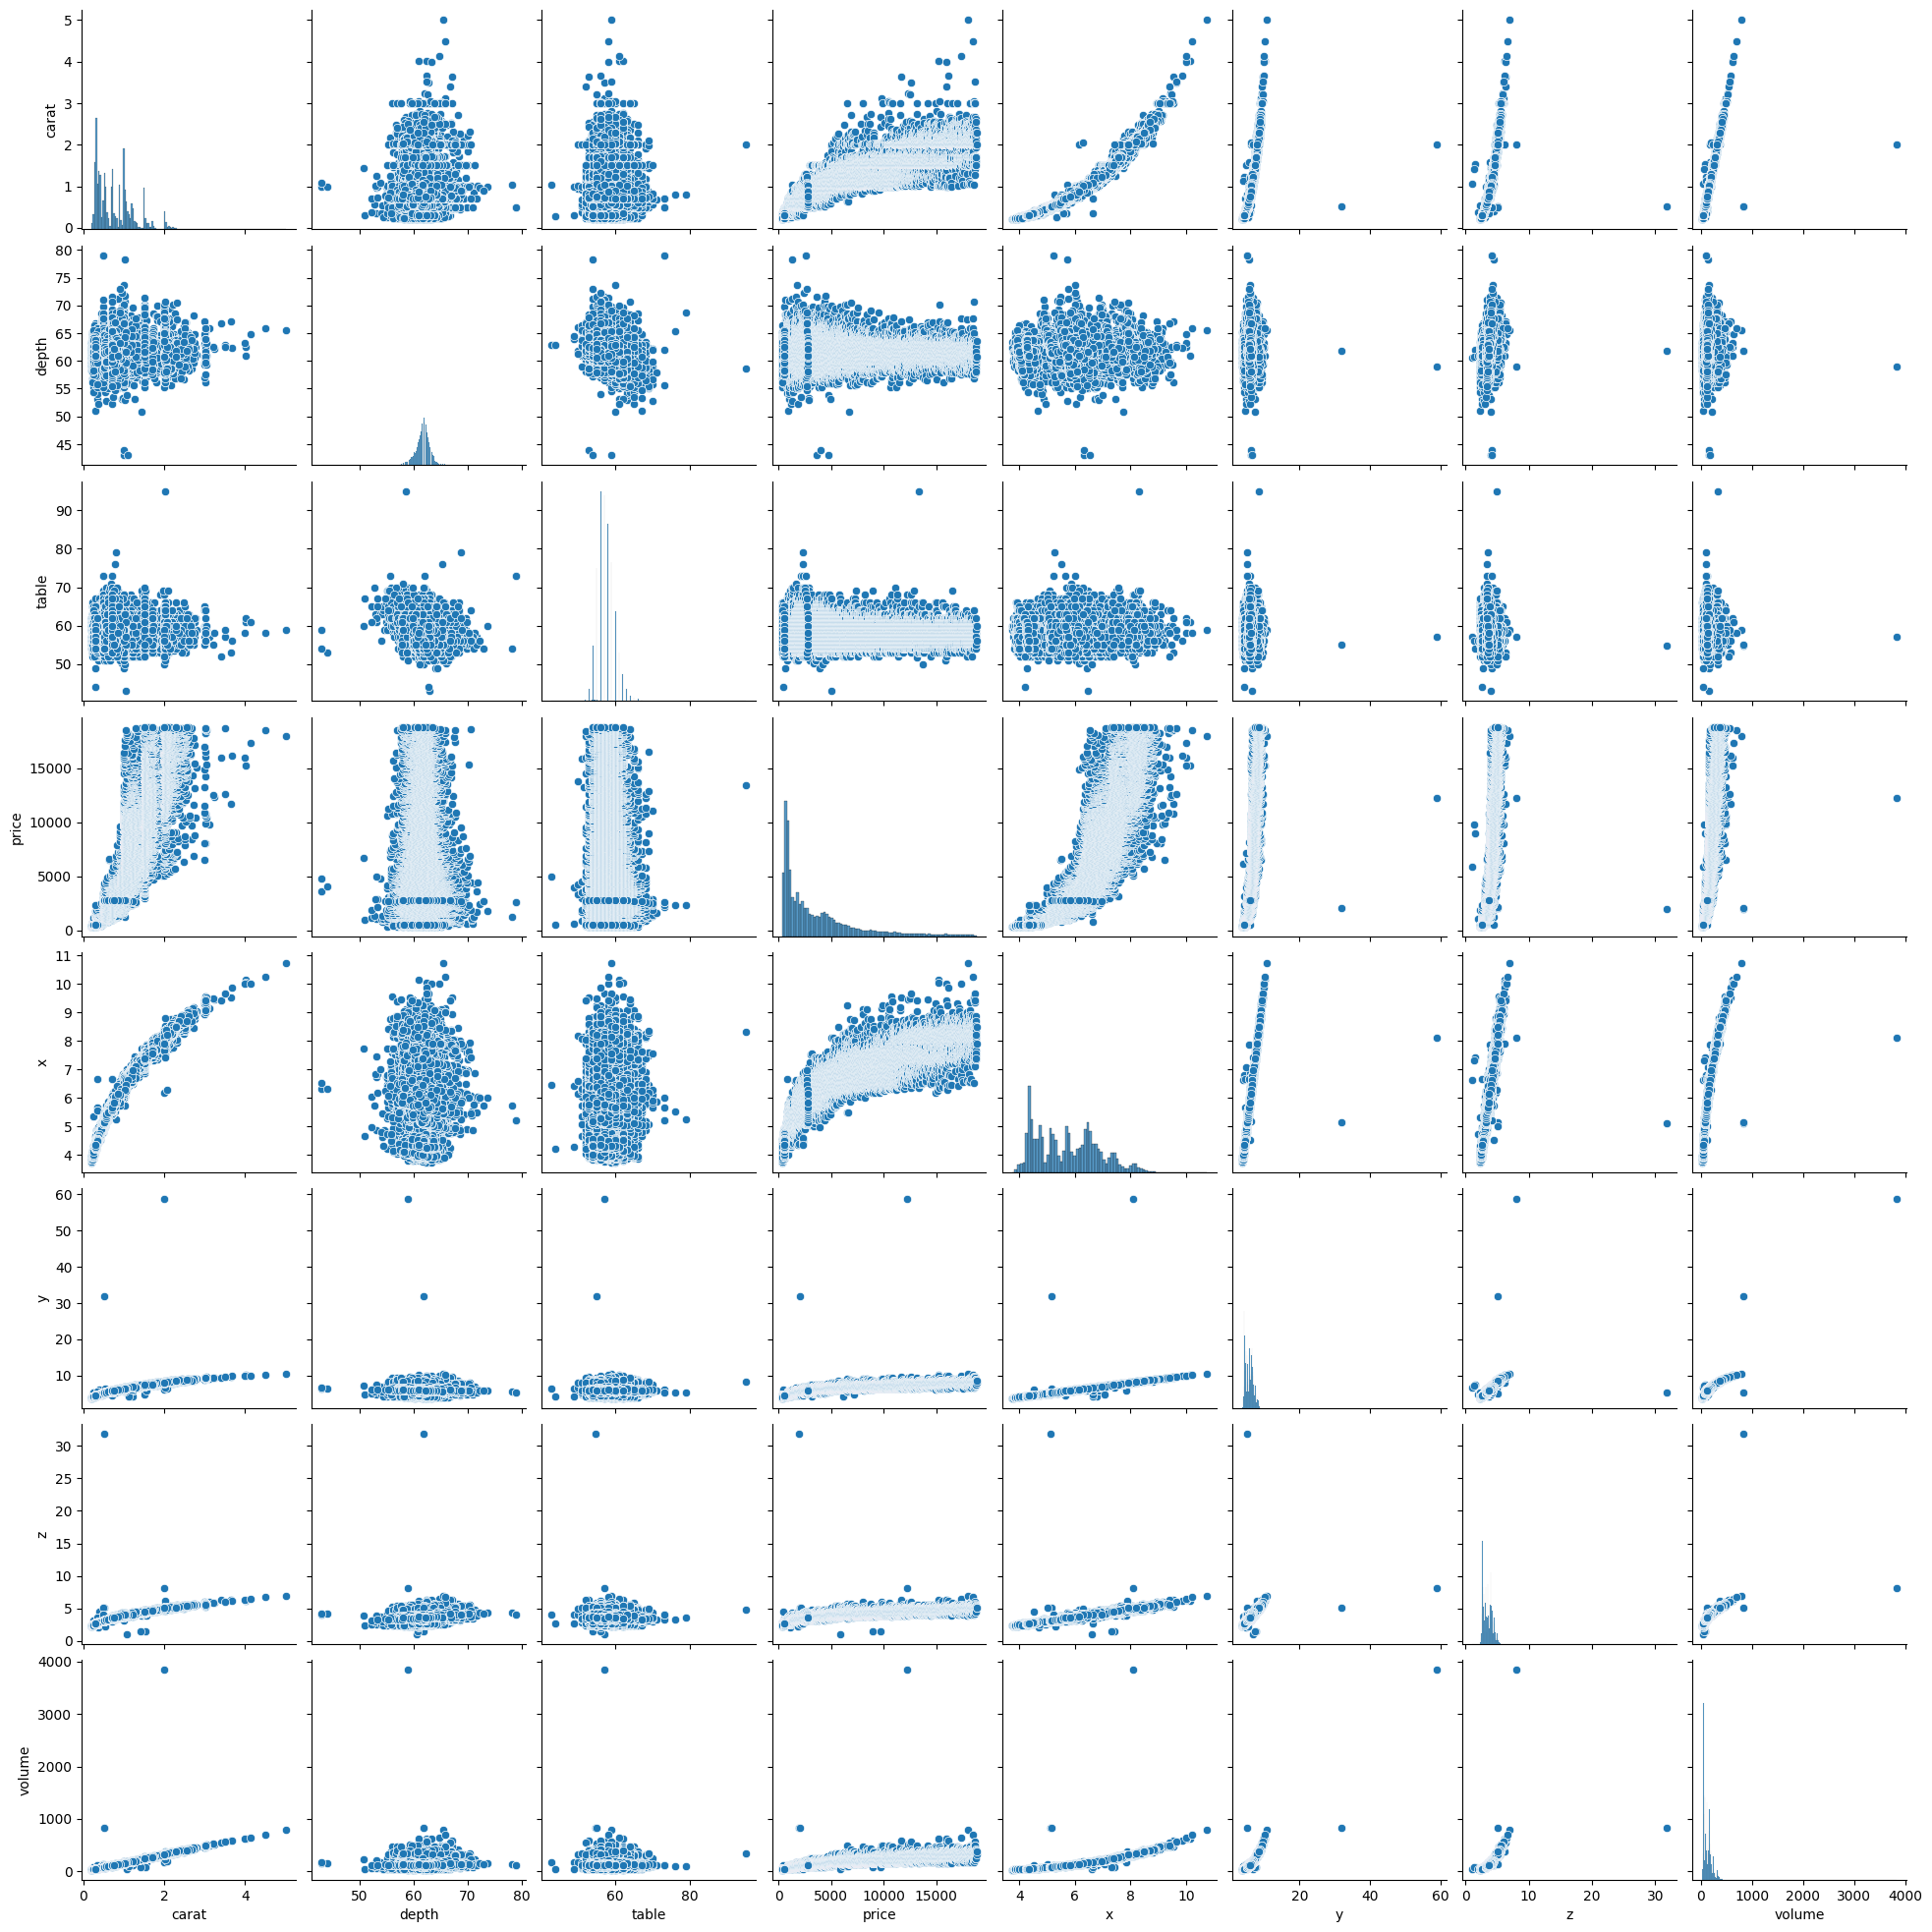

In [8]:
sns.pairplot(df)
plt.show()

In [9]:
df_final = pd.get_dummies(df, columns=['cut', 'color', 'clarity'], drop_first=True)
df_final.head()

,carat,depth,table,price,x,y,z,volume,cut_Good,cut_Ideal,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,38.202030,False,True,...,False,False,False,False,False,True,False,False,False,False
1,0.21,59.8,61.0,326,3.89,3.84,2.31,34.505856,False,False,...,False,False,False,False,True,False,False,False,False,False
2,0.23,56.9,65.0,327,4.05,4.07,2.31,38.076885,True,False,...,False,False,False,False,False,False,True,False,False,False
3,0.29,62.4,58.0,334,4.20,4.23,2.63,46.724580,False,False,...,False,True,False,False,False,False,False,True,False,False
4,0.31,63.3,58.0,335,4.34,4.35,2.75,51.917250,True,False,...,False,False,True,False,False,True,False,False,False,False


### dependent & independent features

In [10]:
X = df_final.drop(['price', 'depth', 'table', 'volume', 'x', 'y', 'z'], axis=1)
y = df_final['price']

In [11]:
X.head()

,carat,cut_Good,cut_Ideal,cut_Premium,cut_Very Good,color_E,color_F,color_G,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,False,True,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False
1,0.21,False,False,True,False,True,False,False,False,False,False,False,True,False,False,False,False,False
2,0.23,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False
3,0.29,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False
4,0.31,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False


In [12]:
y.head()

0    326
1    326
2    327
3    334
4    335
Name: price, dtype: int64

### train - test split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 15)

### pipeline

In [14]:
def poly_regression(degree):
    poly_features = PolynomialFeatures(degree = degree)
    lin_reg = LinearRegression()
    scaler = StandardScaler()
    pipeline = Pipeline([
        ("standar_scaler", scaler),
        ("poly_features", poly_features),
        ("lin_reg", lin_reg)
    ])
    pipeline.fit(X_train, y_train)
    score = pipeline.score(X_test, y_test)
    print("score: ", score)

In [15]:
poly_regression(1)

score:  0.9151173421759615


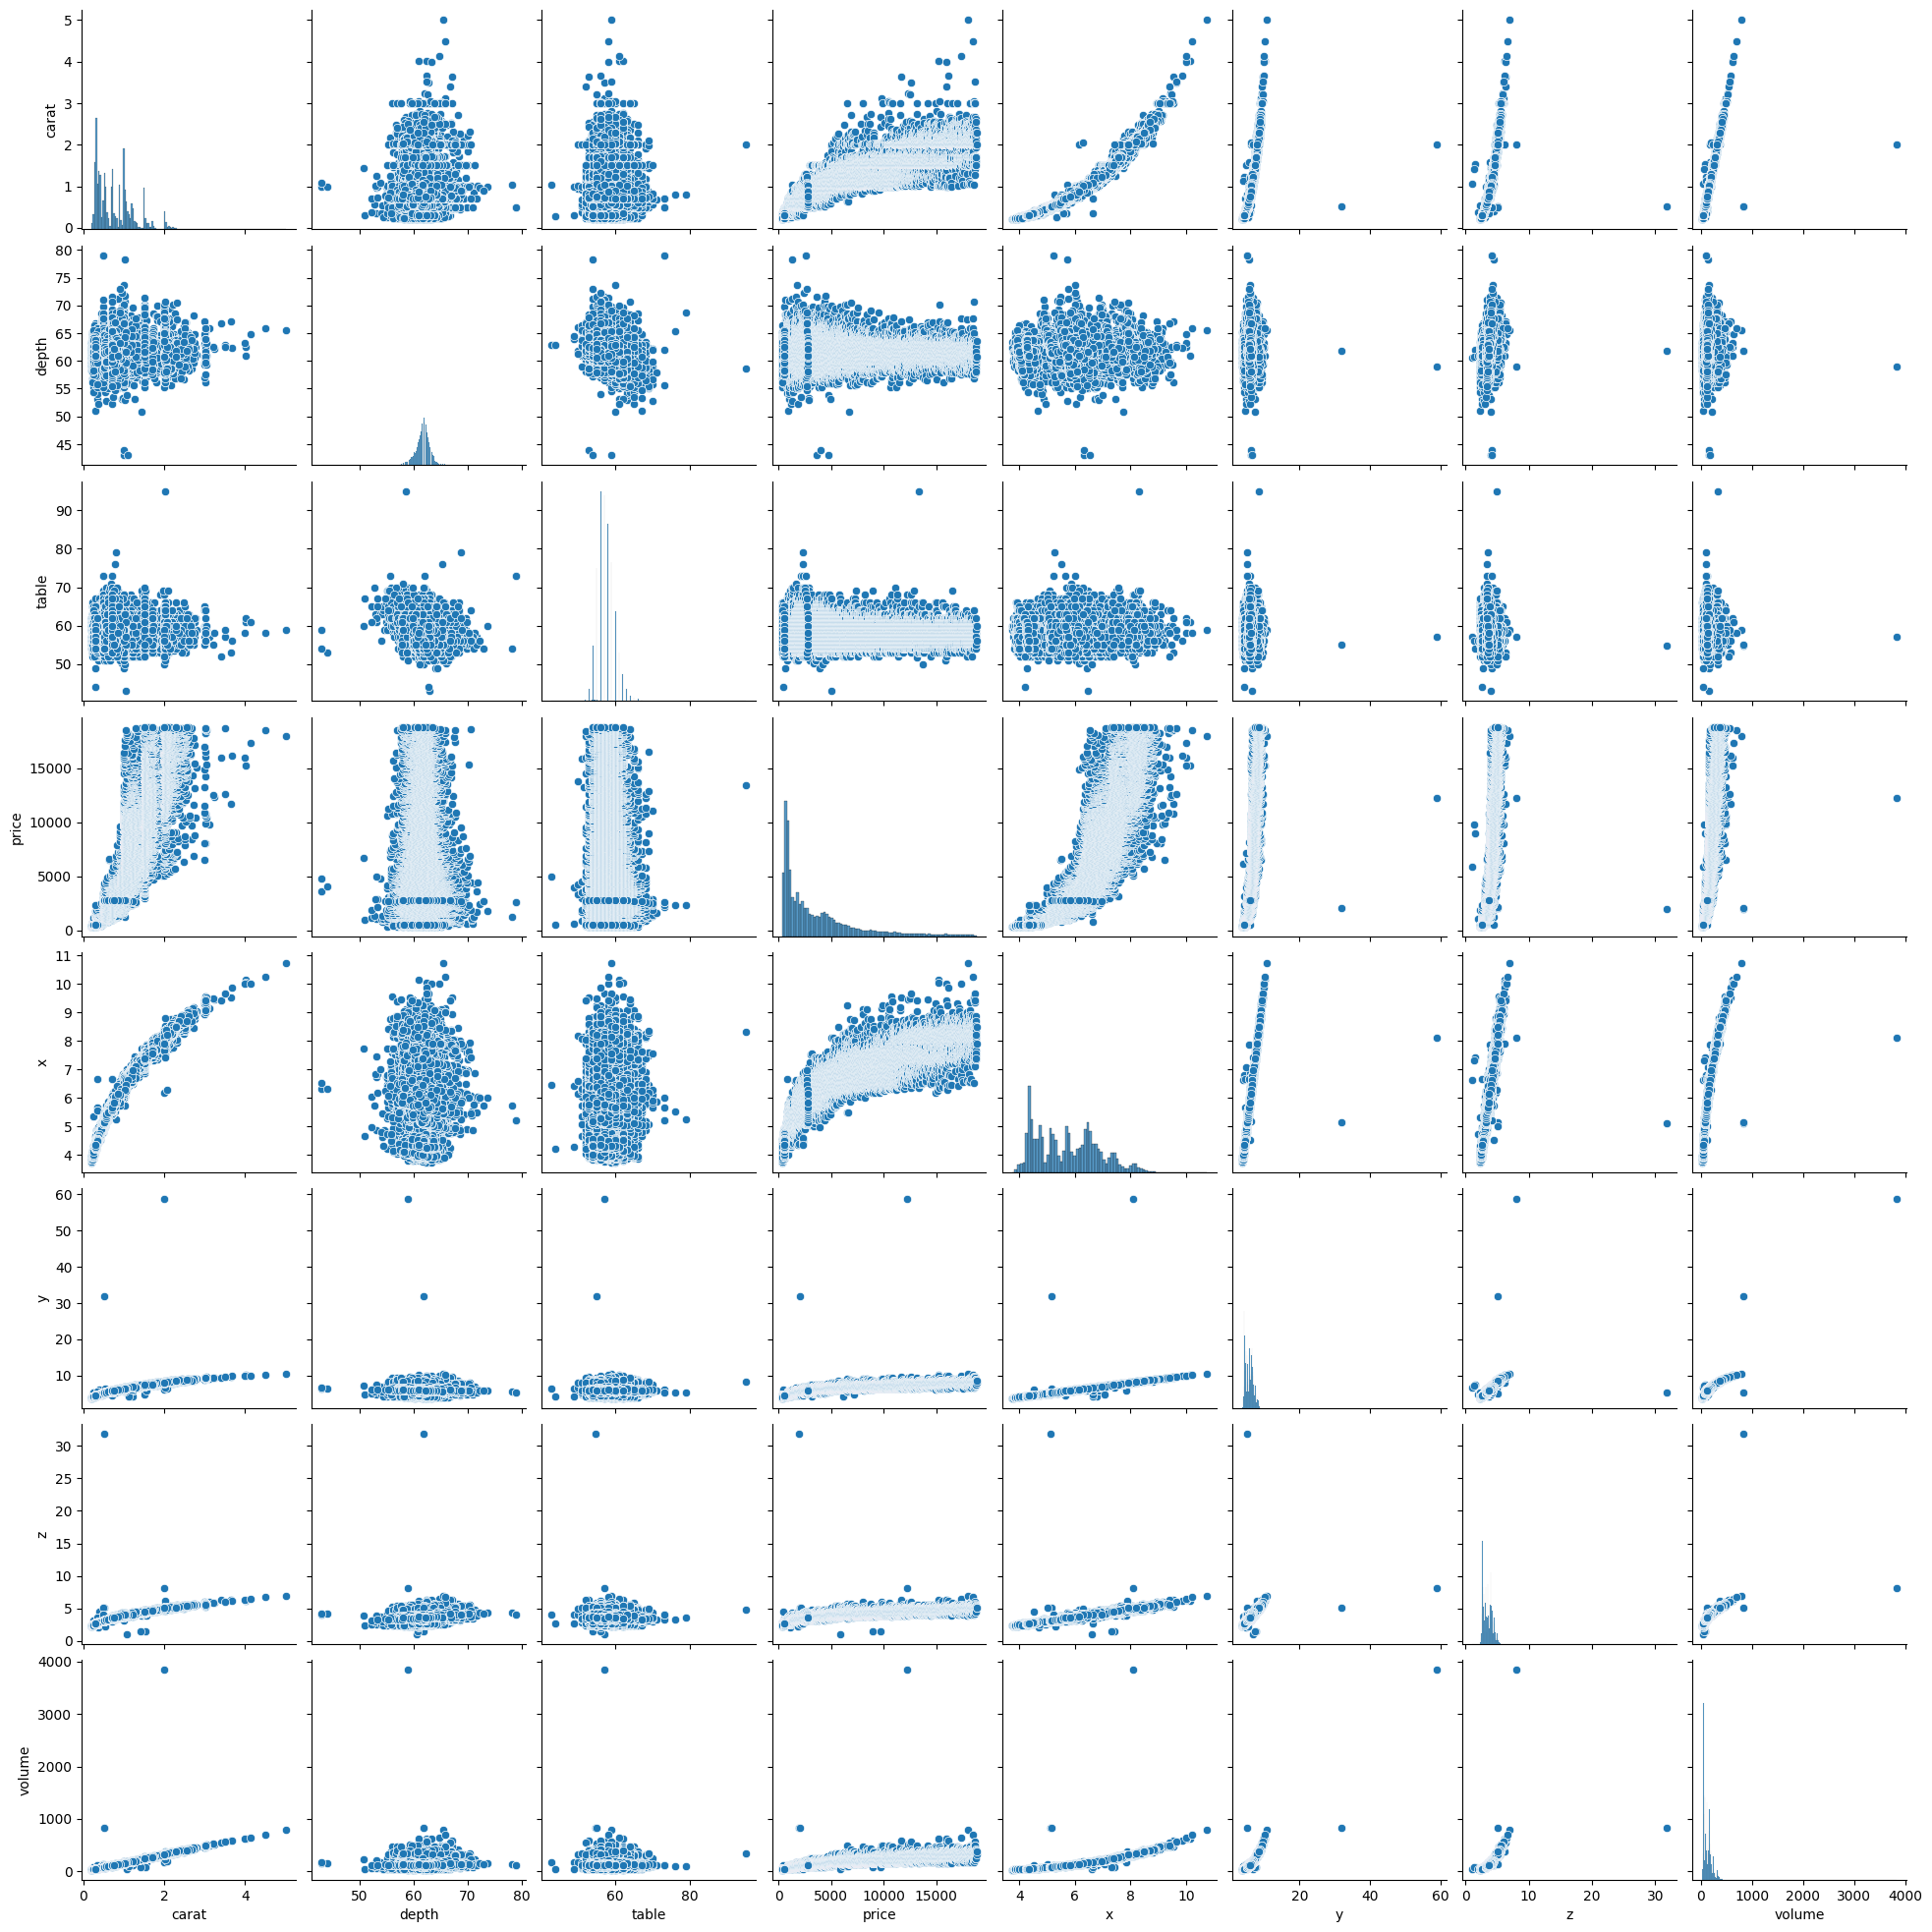

In [16]:
df_numeric = df.select_dtypes(include=['number'])
sns.pairplot(df_numeric)
plt.show()

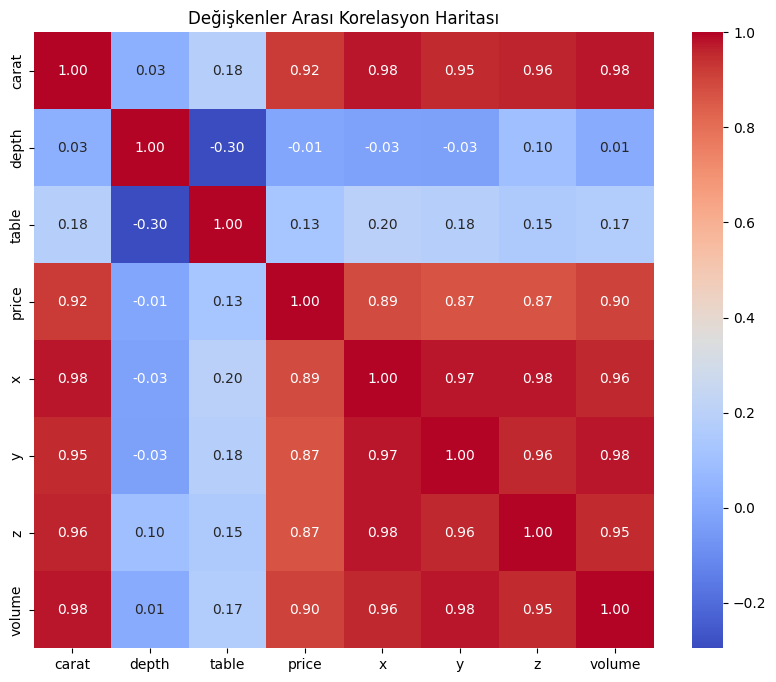

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Değişkenler Arası Korelasyon Haritası")
plt.show()

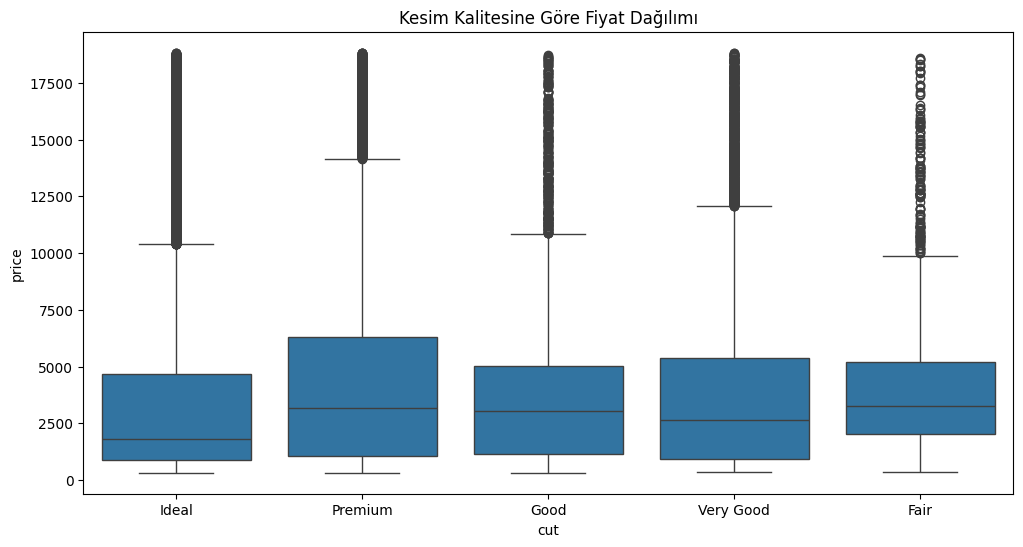

In [18]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='cut', y='price', data=df)
plt.title("Kesim Kalitesine Göre Fiyat Dağılımı")
plt.show()